In [11]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

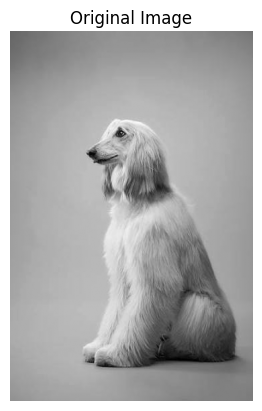

In [10]:
img = cv2.imread('/content/dog.jpeg', 0)

plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.axis('off')
plt.show()

In [17]:
F = np.fft.fftshift(np.fft.fft2(img))
M, N = img.shape

In [13]:
u, v = np.meshgrid(
    np.arange(N) - N//2,
    np.arange(M) - M//2
)

D = np.sqrt(u**2 + v**2)

In [14]:
LPF = D < 30
HPF = D >= 30

In [15]:
smooth = np.abs(
    np.fft.ifft2(np.fft.ifftshift(F * LPF))
)

high_pass = np.abs(
    np.fft.ifft2(np.fft.ifftshift(F * HPF))
)

sharp = np.clip(
    img.astype(float) + high_pass, 0, 255
)

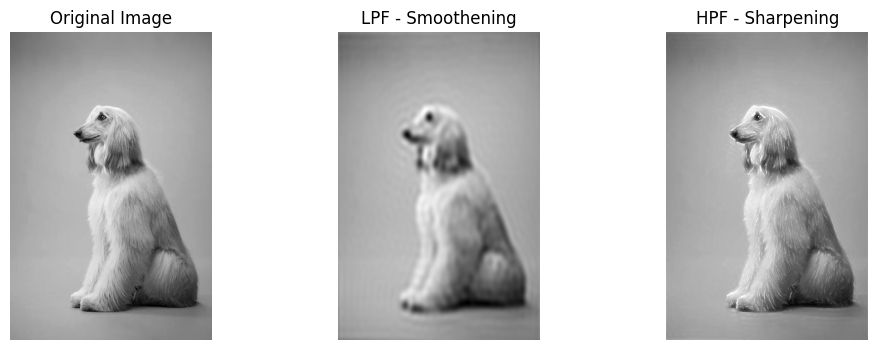

In [16]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(smooth, cmap='gray')
plt.title('LPF - Smoothening')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(sharp, cmap='gray')
plt.title('HPF - Sharpening')
plt.axis('off')

plt.show()